# Fast Feature Search

> **Overview.** Feature search (04) with the fast learning of 04a and the growth of 04c, with 2 to 8 target LTUs:
> the notebook where the pieces of feature search come together.

Search over features (`04_feature_search.ipynb`) with the LTUs learning fast once they have the right inputs
(`04a_fast_feature_learning.ipynb`, `04b_wrong_inputs.ipynb`) and growing into the right inputs
(`04c_growing_features.ipynb`). The notebook where the pieces of feature search come together. With growth, do sampled
LTUs find features with 4 and 8 target LTUs, where fast learning alone found almost none, and does search still help?

**Problem.** As in `04_feature_search.ipynb`: $N = 1000$ standard normal inputs, and the target is
$\frac{1}{\sqrt{K}} \sum_{k=1}^{K} \mathrm{sign}(w_k \cdot x_k)$ plus $N(0, 0.1^2)$ noise, where target LTU $k$ reads
$x_k$, the $k$-th block of 10 inputs, with random $\pm 1$ weights $w_k$. The best possible RMSE is 0.1 (dotted line),
and the best linear learner's about 0.61 for every $K$ (dashed line). Each seed has its own target weights; a run with
$K$ target LTUs uses the first $K$ of the seed's 8.

**Learner.** As in `04_feature_search.ipynb`: the linear learner, a bias, and 32 hidden LTUs (sigmoid derivative
backward) with fixed shadow output weights, +1 and -1 alternately, standardized online; network Autostep
(`squared_inputs`, initial step-size $10^{-4}$, meta step-size 0.02, $\tau = 10^4$). The linear learner learns alone for
the first 100k steps; then the LTUs are added, each reading 1 to 20 inputs (its fan-in uniform) drawn without
replacement with probability proportional to the square of the linear learner's weight on each, and everything learns
for 500k more steps.

**Fast learning** (`04a_fast_feature_learning.ipynb`): a new LTU's input weights start with LeCun uniform magnitudes
over its fan-in and the signs of the linear learner's weights on those inputs times the LTU's shadow weight, and their
step-sizes start at $3 \times 10^{-2}$.

**Growth** (`04c_growing_features.ipynb`): each LTU keeps, for every input it does not read, the sum since its last new
connection (or since it was added or rewired) of the gradient the weight on that input would get,
$\partial L / \partial z \cdot x_i$ ($z$ the LTU's pre-activation). Every 1k steps, if the largest sum in magnitude is
more than 6 times the root mean square of the sums over the inputs it does not read, the LTU connects that input, with
weight 0 and step-size $3 \times 10^{-2}$, and its sums restart.

**Search.** Every $P$ steps after the LTUs are added, the 4 LTUs with the smallest output weight magnitude are replaced
by new ones: newly sampled inputs, drawn as when the LTUs were added but from the linear learner's current weights, an
output weight of 0, fresh statistics and Autostep state, and input weights started as above; each keeps its shadow
weight.

**Runs.** $K$ = 2, 4 and 8 target LTUs, 5 seeds each; the same seed gives every run the same samples and target
weights. *Growth with fast search* (proposed): $P$ = 2k, 10k and 30k steps. *Growth without search* (proposed): the sampled
LTUs grow and are never replaced. *Fast search* (baseline): $P$ = 2k, 10k and 30k steps, without growth. *Fast learning
without search*: the sampled LTUs are never replaced and do not grow. *Search as in `04_feature_search.ipynb`* (baseline): input weights LeCun uniform with step-size
$10^{-4}$, $P$ = 2k, its best. *Fully connected* (baseline): the linear learner and 32 LTUs reading every input, all
learning from the first step, the LTUs' input weights LeCun uniform over the 1,000 inputs, with no fast learning, growth
or search. *LTUs reading one target LTU's inputs* (reference): each pair of LTUs reads one target
LTU's 10 inputs, with fast learning, no search and no growth. *Linear learner* (baseline): no LTUs. Curves are the mean over seeds
of the RMSE averaged over windows of 1k steps; final performance is the RMSE over the last 10% of steps.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_SOURCES = 10                       # each target LTU reads its own block of N_SOURCES inputs, from the first
NOISE_STD = 0.1                      # observation noise on the target: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # the best linear learner's RMSE

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32                          # hidden LTUs
MAX_FAN_IN = 20                      # LTUs with sampled inputs read 1 to MAX_FAN_IN of them
REPLACED = 4                         # LTUs replaced at each search step, those with the smallest |output weight|
FAST_STEP_SIZE = 3e-2                # initial step-size of the input weights of LTUs that learn fast
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest

# --- Experiment ---
LINEAR_STEPS = 100_000               # the linear learner learns alone for this many steps, then the LTUs are added
NUM_STEPS = 500_000                  # steps after the LTUs are added
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
TARGET_COUNTS = (2, 4, 8)            # target LTUs
PERIODS = (2_000, 10_000, 30_000)    # steps between search steps

## Learner

In [3]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped (units,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, 1 (the bias)], of which they read those in `reads`;
    # w['output'] is the output's weights over [inputs (the linear learner), the hidden units, 1]. `mask` says which of
    # the output's connections exist; the hidden units' are switched on when the units are added.
    w: dict                     # {'hidden': (slots, N_INPUTS + 1), 'output': (1, N_INPUTS + slots + 1)}
    reads: jax.Array            # (slots, N_INPUTS + 1)
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (slots,): each hidden unit's shadow output weight, +-1, or 0 for an empty slot
    candidates: jax.Array       # (slots, N_INPUTS): sum of dL/dz * x_i since each unit's last new connection


def init_net(key, units, slots, targets, dense=False):
    # `units` hidden units in `slots` slots, the rest left empty, each pair reading the inputs of one of the `targets`
    # target LTUs in turn (every input if dense) and the bias; their shadow weights +1 and -1 alternately, their input
    # weights LeCun uniform over their fan-in; every other weight at 0.
    target = jnp.arange(slots) // 2 % targets
    reads = jnp.append((jnp.arange(N_INPUTS) // N_SOURCES == target[:, None]) | dense, jnp.ones((slots, 1), bool), axis=1)
    fan_in = N_INPUTS if dense else N_SOURCES
    shadow = jnp.where(jnp.arange(slots) < units, jnp.where(jnp.arange(slots) % 2 == 0, 1.0, -1.0), 0.0)
    mask = jnp.concatenate([jnp.ones(N_INPUTS, bool), jnp.zeros(slots, bool), jnp.ones(1, bool)])[None]
    w = {'hidden': (jax.random.uniform(key, (slots, N_INPUTS + 1), minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((1, N_INPUTS + slots + 1))}
    stats = Stats(jnp.full(slots, 0.5), jnp.zeros(slots), jnp.zeros(slots))
    return Net(w, reads, mask, OPTIMIZER.init(w), stats, shadow, jnp.zeros((slots, N_INPUTS)))


def rewire(net, key, replaced):
    # The `replaced` hidden units (a mask over slots) each read 1 to MAX_FAN_IN inputs (uniform) and the bias, the
    # inputs drawn without replacement with probability proportional to the square of the linear learner's weight on
    # them (Gumbel top-k), with fresh LeCun uniform input weights over their fan-in, output weights at 0, and fresh
    # statistics, Autostep state and gradient sums.
    slots = len(net.shadow)
    fan_key, draw_key, w_key = jax.random.split(key, 3)
    fan_in = jax.random.randint(fan_key, (slots, 1), 1, MAX_FAN_IN + 1)
    scores = jnp.log(net.w['output'][0, :N_INPUTS] ** 2) + jax.random.gumbel(draw_key, (slots, N_INPUTS))
    reads = jnp.append(jnp.argsort(jnp.argsort(-scores)) < fan_in, jnp.ones((slots, 1), bool), axis=1)
    hidden = jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / fan_in) * reads
    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    w = reset(net.w, {'hidden': hidden.at[:, -1].set(0.0), 'output': jnp.zeros_like(net.w['output'])})
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    opt = net.opt._replace(beta=reset(net.opt.beta, jax.tree.map(lambda a: a + net.opt.init_beta, zeros)),
                           h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=w, reads=jnp.where(replaced[:, None], reads, net.reads), opt=opt, stats=stats,
                        candidates=jnp.where(replaced[:, None], 0.0, net.candidates))


def speed_up(net, replaced):
    # The `replaced` hidden units' input weights keep their magnitudes but take the signs of the linear learner's
    # weights on those inputs times the unit's shadow weight, and their step-sizes start at FAST_STEP_SIZE.
    inputs = net.reads.at[:, -1].set(False) & replaced[:, None]
    signs = jnp.sign(net.shadow[:, None] * jnp.append(net.w['output'][0, :N_INPUTS], 0.0))
    hidden = jnp.where(inputs, jnp.abs(net.w['hidden']) * signs, net.w['hidden'])
    beta = jnp.where(inputs, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': hidden}, opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def grow(net):
    # Each hidden unit whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their
    # root mean square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    best = jnp.argmax(sums, 1)
    grows = (jnp.max(sums, 1) > GROW_Z * rms) & (net.shadow != 0)
    new = (jnp.arange(N_INPUTS + 1) == best[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error, each shadow weight standing in for its hidden
    # unit's output weight in the backward pass while the real one is smaller in magnitude. Returns the new network and
    # the squared error on this sample, before learning from it, and adds dL/dz * x_i to each hidden unit's gradient
    # sums. `probe` is zero; its gradients are the error arriving at each hidden unit and dL/dz.
    units = len(net.shadow)

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}
        b = ltu(w['hidden'] @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = h + probe[0]
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][0, N_INPUTS:N_INPUTS + units]
        through_back = jnp.sum(jnp.where(jnp.abs(unit_w) < 1.0, net.shadow, unit_w) * net.mask[0, N_INPUTS:-1] * a)
        prediction = (w['output'] @ jax.lax.stop_gradient(source) + through_back
                      - jax.lax.stop_gradient(through_back))
        sources = {'hidden': jnp.append(x, 1.0) * net.reads,
                   'output': jax.lax.stop_gradient(source)[None] * net.mask}
        return 0.5 * jnp.sum((prediction - y) ** 2), (sources, jax.lax.stop_gradient(h), mean)

    (loss, (sources, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, (jnp.zeros(units),) * 2)
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    error, dz = error
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x), 2 * loss

## Training

In [4]:
def train(net, key, targets, sampled, period, fast, grows, add_step, num_steps):
    # num_steps online network-Autostep steps on targets from this seed's first `targets` target LTUs, the hidden units
    # added at add_step (first rewired if sampled), and every `period` steps after that (never if period is 0) the
    # REPLACED of them with the smallest |output weight| rewired; every unit added or rewired sped up if fast, and
    # every WINDOW steps after the units are added, each grows if grows (before any rewiring). Returns each window's
    # mean squared error.
    target_key, key = jax.random.split(key)
    wire_key = jax.random.fold_in(target_key, 1)
    target_w = jax.random.rademacher(target_key, (max(TARGET_COUNTS), N_SOURCES), dtype=float)
    used = jnp.arange(max(TARGET_COUNTS)) < targets

    def one_step(net, inputs):
        step, key = inputs
        x_key, noise_key = jax.random.split(key)
        x = jax.random.normal(x_key, (N_INPUTS,))
        blocks = x[:target_w.size].reshape(target_w.shape)
        y = (jnp.sum(jnp.where(jnp.sum(target_w * blocks, 1) > 0, 1.0, -1.0) * used) / jnp.sqrt(targets)
             + NOISE_STD * jax.random.normal(noise_key, (1,)))
        net = net._replace(mask=net.mask.at[0, N_INPUTS:-1].set((step >= add_step) & (net.shadow != 0)))
        return learn(net, x, y)

    def start(net, key, replaced, rewired):
        # The replaced units rewired (if rewired) and sped up (if fast).
        net = jax.tree.map(lambda a, b: jnp.where(rewired, a, b), rewire(net, key, replaced), net)
        return jax.tree.map(lambda a, b: jnp.where(fast, a, b), speed_up(net, replaced), net)

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(one_step, net, (index * WINDOW + jnp.arange(WINDOW), jax.random.split(key, WINDOW)))
        since_added = (index + 1) * WINDOW - add_step
        net = jax.tree.map(lambda a, b: jnp.where(grows & (since_added > 0), a, b), grow(net), net)
        due = (period > 0) & (since_added > 0) & (since_added % jnp.maximum(period, 1) == 0)
        weakest = jnp.argsort(jnp.where(net.shadow != 0, jnp.abs(net.w['output'][0, N_INPUTS:-1]), jnp.inf))[:REPLACED]
        searched = start(net, jax.random.fold_in(wire_key, index), jnp.zeros(len(net.shadow), bool).at[weakest].set(True),
                         True)
        return jax.tree.map(lambda a, b: jnp.where(due, a, b), searched, net), mse.mean()

    n, added = num_steps // WINDOW, add_step // WINDOW
    index, keys = jnp.arange(n), jax.random.split(key, n)
    net, before = jax.lax.scan(window, net, (index[:added], keys[:added]))
    net = start(net, wire_key, net.shadow != 0, sampled)
    return jnp.concatenate([before, jax.lax.scan(window, net, (index[added:], keys[added:]))[1]])


def run(configs, dense=False):
    # Each (units, targets, sampled, period, fast, grows) of configs: `units` hidden LTUs reading sampled inputs if
    # sampled, searched every `period` steps (0: never), and one target LTU's inputs otherwise (no LTUs: the linear
    # learner alone), learning fast if fast and growing if grows, on `targets` target LTUs, each on N_SEEDS seeds,
    # vmapped together. Seed s gives every run the same samples and target weights. Returns {config: the RMSE of each
    # window from step 1, shaped (seed, window)}. If dense, every LTU reads every input and learns from the first step.
    units, targets, sampled, period, fast, grows, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs
                                                                                       for s in range(N_SEEDS)]))
    slots = max(max(c[0] for c in configs), 1)
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    nets = jax.vmap(lambda k, u, t: init_net(k, u, slots, t, dense))(keys(0), units, targets)
    train_all = jax.jit(jax.vmap(lambda n, k, t, s, p, f, g: train(n, k, t, s, p, f, g, 0 if dense else LINEAR_STEPS,
                                                                      LINEAR_STEPS + NUM_STEPS)))
    mse = train_all(nets, keys(1), targets, sampled, period, fast, grows)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))

## Runs

In [5]:
BASELINE_PERIOD = 2_000              # the search period of search as in 04_feature_search.ipynb, its best there
started = perf_counter()
linear = run([(0, k, False, 0, False, False) for k in TARGET_COUNTS])
dense = run([(N_LTUS, k, False, 0, False, False) for k in TARGET_COUNTS], dense=True)
ltus = run([(N_LTUS, k, *c) for k in TARGET_COUNTS
            for c in [(True, BASELINE_PERIOD, False, False), (True, 0, True, False), (False, 0, True, False)]
            + [(True, p, True, False) for p in PERIODS]])
ltus |= run([(N_LTUS, k, True, p, True, True) for k in TARGET_COUNTS for p in (0, *PERIODS)])   # apart: one big batch runs slower
print(f'{(len(linear) + len(dense) + len(ltus)) * N_SEEDS} runs in {perf_counter() - started:.0f}s')
linear = {k: linear[(0, k, False, 0, False, False)] for k in TARGET_COUNTS}
dense = {k: dense[(N_LTUS, k, False, 0, False, False)] for k in TARGET_COUNTS}
slow_search = {k: ltus[(N_LTUS, k, True, BASELINE_PERIOD, False, False)] for k in TARGET_COUNTS}
no_search = {k: ltus[(N_LTUS, k, True, 0, True, False)] for k in TARGET_COUNTS}
reference = {k: ltus[(N_LTUS, k, False, 0, True, False)] for k in TARGET_COUNTS}
search = {p: {k: ltus[(N_LTUS, k, True, p, True, False)] for k in TARGET_COUNTS} for p in PERIODS}
grown = {p: {k: ltus[(N_LTUS, k, True, p, True, True)] for k in TARGET_COUNTS} for p in (0, *PERIODS)}

180 runs in 236s


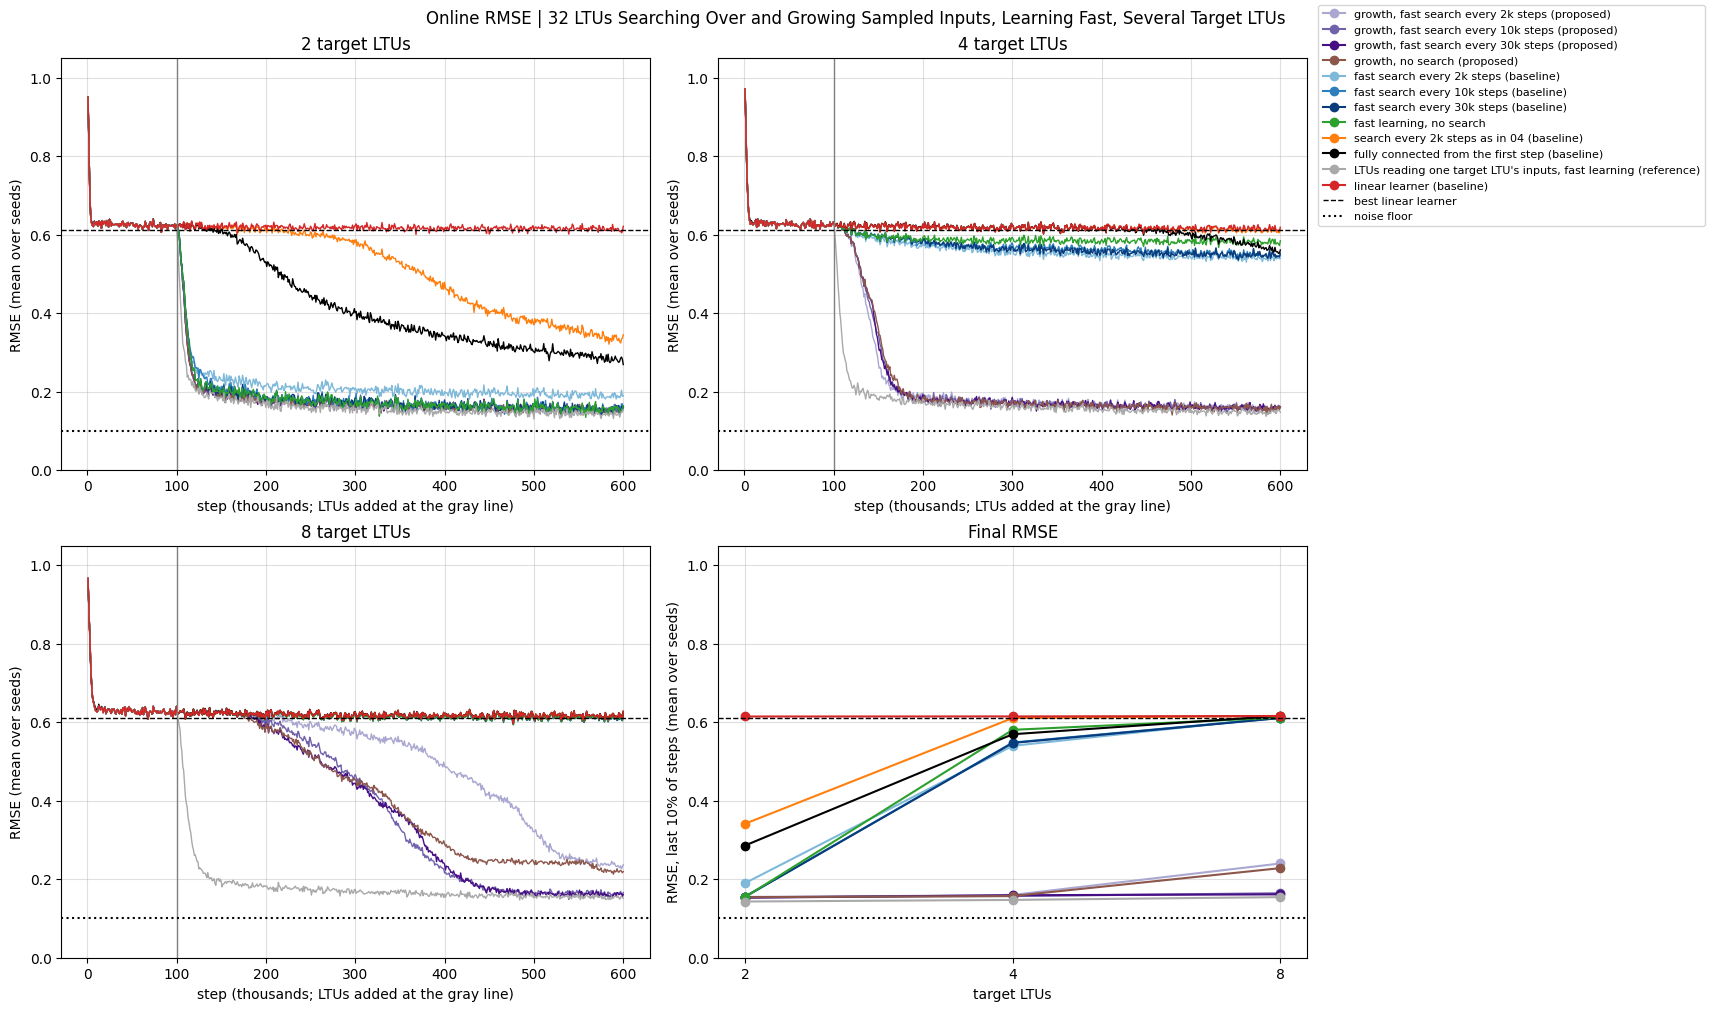

In [6]:
STEPS = (np.arange((LINEAR_STEPS + NUM_STEPS) // WINDOW) + 1) * WINDOW
METHODS = {**{f'growth, fast search every {p // 1000}k steps (proposed)': (grown[p], color)
              for p, color in zip(PERIODS, plt.cm.Purples(np.linspace(0.45, 0.95, len(PERIODS))))},
           'growth, no search (proposed)': (grown[0], 'tab:brown'),
           **{f'fast search every {p // 1000}k steps (baseline)': (search[p], color)
              for p, color in zip(PERIODS, plt.cm.Blues(np.linspace(0.45, 0.95, len(PERIODS))))},
           'fast learning, no search': (no_search, 'tab:green'),
           f'search every {BASELINE_PERIOD // 1000}k steps as in 04 (baseline)': (slow_search, 'tab:orange'),
           'fully connected from the first step (baseline)': (dense, 'black'),
           "LTUs reading one target LTU's inputs, fast learning (reference)": (reference, 'darkgray'),
           'linear learner (baseline)': (linear, 'tab:red')}
final = lambda rmse: rmse[:, -(NUM_STEPS // WINDOW // 10):].mean(1)   # each seed's RMSE over the last 10% of steps

fig, axes = plt.subplot_mosaic([[2, 4], [8, 'final']], figsize=(17, 10), layout='constrained')
for k in TARGET_COUNTS:
    ax = axes[k]
    for label, (runs, color) in METHODS.items():
        ax.plot(STEPS / 1000, runs[k].mean(0), color=color, lw=1, label=label)
    ax.axvline(LINEAR_STEPS / 1000, color='gray', lw=1)
    ax.set(xlabel='step (thousands; LTUs added at the gray line)', ylabel='RMSE (mean over seeds)', ylim=(0, 1.05),
           title=f'{k} target LTU{"s" if k > 1 else ""}')

ax = axes['final']
for label, (runs, color) in METHODS.items():
    ax.plot(TARGET_COUNTS, [final(runs[k]).mean() for k in TARGET_COUNTS], 'o-', color=color, label=label)
ax.set_xscale('log', base=2)
ax.set_xticks(TARGET_COUNTS, [str(n) for n in TARGET_COUNTS])
ax.set(xlabel='target LTUs', ylabel='RMSE, last 10% of steps (mean over seeds)', ylim=(0, 1.05), title='Final RMSE')
for ax in axes.values():
    ax.axhline(LINEAR_RMSE, color='black', ls='--', lw=1, label='best linear learner')
    ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
    ax.grid(alpha=0.4)
fig.legend(*axes['final'].get_legend_handles_labels(), loc='outside right upper', fontsize=8)
fig.suptitle(f'Online RMSE | {N_LTUS} LTUs Searching Over and Growing Sampled Inputs, Learning Fast, Several Target LTUs')
plt.show()

## Results

5 seeds per configuration. The notebook takes about 4 minutes.

- **Growth lets sampled LTUs find the features.** With 8 target LTUs, growth with search every 10k or 30k steps ends at
  RMSE 0.16, near the reference's 0.155, where every run without growth stays at the linear learner's 0.61. With 4
  target LTUs, growth ends at 0.16, against 0.55 for fast search.
- **A fully connected network does no better than the linear learner with 8 target LTUs** (0.616), and ends at 0.57
  with 4 and 0.29 with 2.
- **With 8 target LTUs it is slow**: the RMSE barely moves for the first 100k steps after the LTUs are added, and reaches
  0.2 after a median 270k to 290k steps (the reference: 32k).
- **Search still helps, at a long enough period**: with 8 target LTUs, growth without search ends at 0.23 (2 of 5 seeds
  stall at 0.27 and 0.35), and growth with search every 2k steps at 0.24 (one seed stuck at 0.5).